# The traveling salesman problem with QAOA

## The problem

A salesperson must visit every city exactly once and return home, as cheaply as
possible. Given the cost of travel between each pair of cities, find the
cheapest **tour**. With $n$ cities there are $(n-1)!$ tours, so brute force
stops being practical quickly. TSP is the classic example of a **combinatorial
optimization** problem, and the same recipe applies to scheduling, routing, and
many others.

We solve it the way a quantum computer wants to see it: write the cost as a
**Hamiltonian** whose ground state is the cheapest tour, then search for that
ground state with **QAOA**, a variational algorithm.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Encoding | Write a tour as a bitstring; build the ansatz | `encoding.py` |
| 2. Operator | Turn the cost into a Hamiltonian (via a QUBO) | `ops.py` |
| 3. Execution | Run the loop on a simulator or hardware | `execution.py` |
| 4. Analysis | Decode, rank the tours, and plot | `analysis.py` |

The same steps are available as one command,
`python optimization/main.py example_cities.json`. This notebook walks through
them one at a time. The code lives in `../scripts/optimization/` and is imported
here, so the notebook and the command line cannot drift apart.

## Setup

By default this notebook runs on the noiseless Aer simulator. To run on IBM
hardware, set `backend_name` to a backend you can access (your saved Qiskit
account is used). Hardware jobs may wait in a queue.

- `cities` and `costs`: the problem. `costs[a][b]` is the cost of going from
  city `a` to city `b`. It need not be symmetric. The first city is the start
  and end of the tour.
- `reps`: the number of QAOA layers. `starts`: how many random starting points
  the optimizer tries. `shots`: samples per measurement.

A problem with $n$ cities needs $(n-1)^2$ qubits, so 4 cities need 9 qubits and
5 cities need 16. The simulator handles up to about 5 cities.

In [1]:
import sys
import tempfile
from itertools import product
from math import factorial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image

# The TSP code lives in ../scripts/optimization.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/optimization").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

cities = ["Troy", "Albany", "Schenectady", "Saratoga"]
costs = np.array(
    [
        [0, 15, 25, 35],
        [15, 0, 20, 40],
        [25, 20, 0, 25],
        [35, 40, 25, 0],
    ]
)
backend_name = None  # None = Aer simulator; or e.g. "ibm_rensselaer"
reps = 2
starts = 3
shots = 4096

n = len(cities)
print(f"{n} cities, {enc.n_qubits(n)} qubits")
print(f"{'':>12}" + "".join(f"{c:>12}" for c in cities))
for name, row in zip(cities, costs):
    print(f"{name:>12}" + "".join(f"{v:>12g}" for v in row))

4 cities, 9 qubits
                    Troy      Albany Schenectady    Saratoga
        Troy           0          15          25          35
      Albany          15           0          20          40
 Schenectady          25          20           0          25
    Saratoga          35          40          25           0


## Step 1: Encoding a tour as a bitstring

A tour is an ordering of the cities. We store it as a table of yes/no answers:

$$x_{c,t} = 1 \quad\text{if city } c \text{ is visited at step } t.$$

One bit, one qubit. The tour has to start and end at a fixed place, so we fix
city 0 at step 0. That removes the symmetry between rotated copies of the same
loop and saves qubits. The other $n-1$ cities and the other $n-1$ steps make an
$(n-1)\times(n-1)$ table, so we need $(n-1)^2$ bits.

A table is a valid tour only if **every row and every column has exactly one 1**
(every city is visited once, and every step holds one city). That is a
*permutation matrix*. The bitstring lists the table row by row: qubit
$(c-1)(n-1) + (t-1)$ holds $x_{c,t}$.

Here is one tour encoded and decoded by hand.

In [2]:
tour = [0, 2, 1, 3]  # Troy -> Schenectady -> Albany -> Saratoga -> Troy
m = n - 1
table = np.zeros((m, m), dtype=int)
for step, city in enumerate(tour[1:]):
    table[city - 1, step] = 1
bits = "".join(map(str, table.flatten()))

print("rows = cities 1..3, columns = steps 1..3")
print(table)
print(f"\nBitstring (qubit 0 first): {bits}")
print("Decoded tour:", analysis.tour_names(enc.decode_tour(bits, n), cities))
print(f"Tour cost: {enc.tour_length(tour, costs):g}")

# Two invalid tables: the decoder returns None for both.
two_in_step_1 = "100100001"  # cities 1 and 2 are both at step 1
city_twice = "110000001"  # city 1 is visited twice, city 2 never
print("\nTwo cities at step 1:", enc.decode_tour(two_in_step_1, n))
print("City 1 twice, city 2 never:", enc.decode_tour(city_twice, n))

rows = cities 1..3, columns = steps 1..3
[[0 1 0]
 [1 0 0]
 [0 0 1]]

Bitstring (qubit 0 first): 010100001
Decoded tour: Troy -> Schenectady -> Albany -> Saratoga -> Troy
Tour cost: 120

Two cities at step 1: None
City 1 twice, city 2 never: None


In [3]:
# Count the valid tours among all bitstrings by checking each one.
n_bits = (n - 1) ** 2
all_bits = ("".join(b) for b in product("01", repeat=n_bits))
n_valid = sum(enc.decode_tour(b, n) is not None for b in all_bits)
print(
    f"{2**n_bits} bitstrings, {n_valid} valid tours "
    f"({n_valid / 2**n_bits:.1%})\n"
)

# The same comparison for more cities (counted with formulas, not by brute
# force): bitstrings grow as 2^((n-1)^2), valid tours as (n-1)!.
print(f"{'cities':>6} {'qubits':>7} {'bitstrings':>16} {'valid tours':>12}")
for k in range(3, 9):
    q = enc.n_qubits(k)
    print(f"{k:>6} {q:>7} {2**q:>16,} {factorial(k - 1):>12,}")

512 bitstrings, 6 valid tours (1.2%)

cities  qubits       bitstrings  valid tours
     3       4               16            2
     4       9              512            6
     5      16           65,536           24
     6      25       33,554,432          120
     7      36   68,719,476,736          720
     8      49 562,949,953,421,312        5,040


### The ansatz

**QAOA** (Quantum Approximate Optimization Algorithm) builds the trial state in
layers. Start in $|+\rangle^{\otimes n}$, an equal superposition of *every*
bitstring, then repeat $p$ times:

$$
|\psi(\boldsymbol\beta,\boldsymbol\gamma)\rangle = \prod_{k=1}^{p} e^{-i\beta_k
H_M}\, e^{-i\gamma_k H_C}\,|+\rangle^{\otimes n}.
$$

- $e^{-i\gamma H_C}$ is the **cost layer**. It gives each bitstring a phase
  proportional to its cost.
- $e^{-i\beta H_M}$ is the **mixer** ($H_M=\sum X_i$). It moves amplitude
  between bitstrings so the phases turn into probabilities.

The $2p$ angles are what the classical optimizer tunes. The cost operator $H_C$
is built in Step 2. To see the structure now, we build the ansatz around a
placeholder operator.

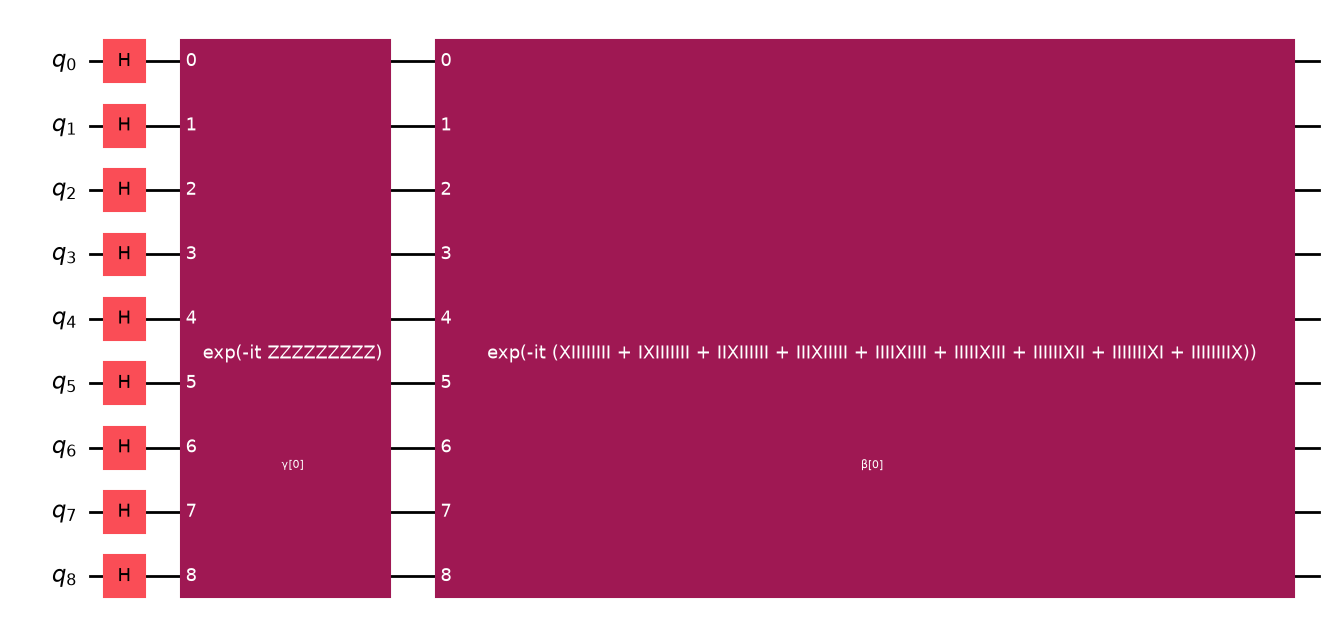

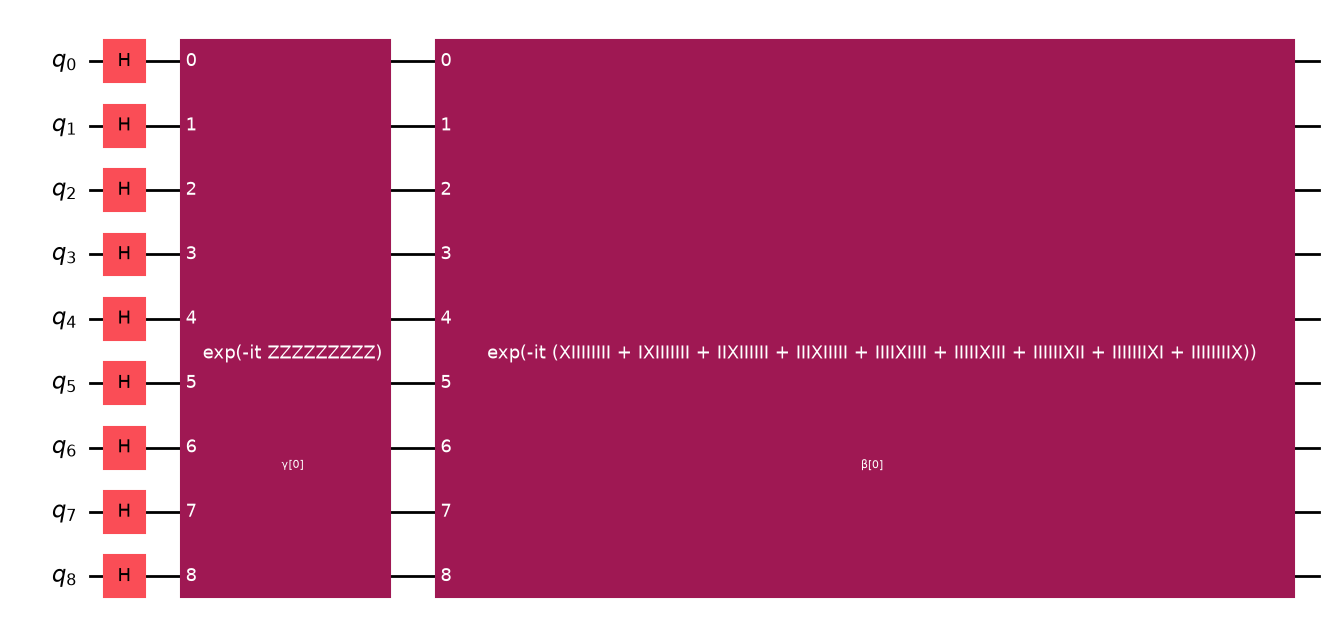

In [4]:
from qiskit.quantum_info import SparsePauliOp

placeholder = SparsePauliOp(
    "Z" * enc.n_qubits(n)
)  # stand-in for the real cost operator
enc.build_ansatz(placeholder, reps=1).decompose().draw("mpl", fold=-1)

## Stop and think: what did the encoding decide?

1. **A tour is a table of bits.** We never store the city order directly. We
   store, for each (city, step) pair, whether it is chosen, and classical code
   reads the order back from the measured bits.
2. **Almost every bitstring is not a tour.** The count above shows it: $n$
   cities give $2^{(n-1)^2}$ bitstrings but only $(n-1)!$ tours. Already at 8
   cities the valid fraction is below one in a hundred billion. The Hamiltonian
   must make all the non-tours expensive.
3. **The qubit count grows as $(n-1)^2$.** This simple one-hot encoding is easy
   to understand and its terms are at most two-body, but it uses many qubits.
   Denser encodings exist (a tour as a permutation needs only about $n\log n$
   bits) at the price of more complicated cost terms. Compare with the folding
   example, where the encoding choice was the main design question.
4. **The ansatz is generic.** QAOA knows nothing about tours. All the
   problem-specific structure will enter through $H_C$.

*Try it:* change `cities` and `costs` to 5 cities and watch the qubit count. How
does the valid fraction change?

## Step 2: The operator (the Hamiltonian)

We need a function of the bits whose minimum is the cheapest tour. Because it is
quadratic in binary variables, this is a **QUBO** (quadratic unconstrained
binary optimization):

$$E(x) = x^T Q x + \text{const},\qquad x_i\in\{0,1\}.$$

It has two parts.

**Travel cost.** Add $d(a,b)$ whenever city $a$ is at step $t$ and city $b$ is
at step $t+1$:

$$\sum_{t}\sum_{a\ne b} d(a,b)\,x_{a,t}\,x_{b,t+1},$$

plus the leg out of city 0 into step 1 and the leg back from step $n-1$.

**Constraints.** Penalize any row or column of the table that does not hold
exactly one 1:

$$
\lambda\sum_c\Big(1-\sum_t x_{c,t}\Big)^2 + \lambda\sum_t\Big(1-\sum_c
x_{c,t}\Big)^2.
$$

These vanish for a valid tour and cost at least $\lambda$ otherwise. The weight
$\lambda$ must exceed the largest possible saving from breaking a rule, so we
use $\lambda = 2\max d$.

Finally, we substitute $x=(1-Z)/2$ for every bit. That turns the QUBO into a sum
of Pauli-$Z$ strings, an **Ising Hamiltonian** $H_C$ that is diagonal in the
computational basis. The energy of a bitstring is the eigenvalue of $H_C$ on it.
The code divides the costs by the longest leg first, which keeps the QAOA angles
in a useful range whatever units you use.

In [5]:
hamiltonian = ops.build_hamiltonian(costs)
labels = hamiltonian.paulis.to_labels()
weights = [sum(ch != "I" for ch in label) for label in labels]

print(f"{hamiltonian.num_qubits} qubits, {len(hamiltonian)} Pauli terms")
print("Terms by number of qubits acted on:")
for w in sorted(set(weights)):
    print(f"  {w}-body: {weights.count(w)}")
penalty = ops.default_penalty(costs / costs.max())
print(f"Penalty weight lambda = {penalty:.1f}")
print("(costs are scaled so that the longest leg is 1)")

9 qubits, 40 Pauli terms
Terms by number of qubits acted on:
  0-body: 1
  1-body: 9
  2-body: 30
Penalty weight lambda = 2.0
(costs are scaled so that the longest leg is 1)


### Does the Hamiltonian have the right ground state?

With 9 qubits we can check by brute force, which is exactly what the quantum
computer is supposed to avoid. Because $H_C$ is diagonal we can read every
energy off its diagonal. The lowest energies should be the valid tours, in order
of cost, and every invalid bitstring should sit above them.

Six lowest-energy bitstrings:
 energy   cost  tour
  2.375     95  Troy -> Saratoga -> Schenectady -> Albany -> Troy
  2.375     95  Troy -> Albany -> Schenectady -> Saratoga -> Troy
  2.625    105  Troy -> Schenectady -> Saratoga -> Albany -> Troy
  2.625    105  Troy -> Albany -> Saratoga -> Schenectady -> Troy
  3.000    120  Troy -> Schenectady -> Albany -> Saratoga -> Troy
  3.000    120  Troy -> Saratoga -> Albany -> Schenectady -> Troy

6 valid tours: energies 2.375 to 3.000
506 invalid bitstrings: lowest energy 4.875


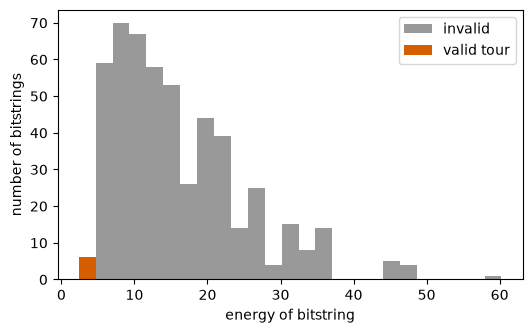

In [6]:
n_q = hamiltonian.num_qubits


def bits_of(i):
    # Basis state i as a bitstring in qubit order (qubit 0 first).
    return "".join(str((i >> k) & 1) for k in range(n_q))


# H is diagonal, so its diagonal entries are the energies of the bitstrings
# 0, 1, 2, ... Decode every bitstring to see which ones are tours.
diag = hamiltonian.to_matrix(sparse=True).diagonal().real
tours = [enc.decode_tour(bits_of(i), n) for i in range(2**n_q)]
is_valid = np.array([t is not None for t in tours])

print("Six lowest-energy bitstrings:")
print(f"{'energy':>7}  {'cost':>5}  tour")
for i in np.argsort(diag)[:6]:
    cost = enc.tour_length(tours[i], costs)
    print(
        f"{diag[i]:>7.3f}  {cost:>5g}  {analysis.tour_names(tours[i], cities)}"
    )

low, high = diag[is_valid].min(), diag[is_valid].max()
print(f"\n{is_valid.sum()} valid tours: energies {low:.3f} to {high:.3f}")
print(
    f"{(~is_valid).sum()} invalid bitstrings: lowest energy "
    f"{diag[~is_valid].min():.3f}"
)

plt.figure(figsize=(6, 3.5))
plt.hist(
    [diag[~is_valid], diag[is_valid]],
    bins=25,
    stacked=True,
    color=["#999999", "#D55E00"],
    label=["invalid", "valid tour"],
)
plt.xlabel("energy of bitstring")
plt.ylabel("number of bitstrings")
plt.legend()
plt.show()

## Stop and think: what is the Hamiltonian doing?

1. **Energy equals the eigenvalue.** $H_C$ is diagonal, so $\langle
   x|H_C|x\rangle$ is the energy of bitstring $x$. For a valid tour that energy
   is the scaled tour cost. An invalid string pays at least one penalty
   $\lambda$ on top, which is why the histogram separates the two groups.
2. **The ground state is the answer.** The lowest eigenvalue is the cheapest
   tour. Notice that a tour and its reverse have the same cost here (the table
   is symmetric), so the ground level is **doubly degenerate**: two bitstrings,
   one answer. With a non-symmetric cost table the degeneracy goes away.
3. **Penalties are a design choice.** Too small a $\lambda$ and an invalid
   string with a tempting "cost" beats a real tour. Too large and the
   differences between real tours become a tiny ripple on a huge landscape,
   which is hard for the optimizer to notice. That is the main practical
   difficulty of QUBO methods.
4. **The terms are at most two-body.** The one-hot encoding keeps every term to
   one or two qubits, so the cost layer needs only $R_{ZZ}$ gates, one per pair
   of coupled qubits. That is friendly to hardware limited to two-qubit gates.

*Try it:* make `costs` non-symmetric (for example change `costs[0][3]` to 5) and
look at the lowest energies again. What happens to the degeneracy?

## Step 3: Execution

Now the variational loop. Each iteration:

1. The classical optimizer (**COBYLA**, a gradient-free method that tolerates
   noisy energies) proposes the angles $(\boldsymbol\beta,\boldsymbol\gamma)$.
2. The quantum computer prepares
   $|\psi(\boldsymbol\beta,\boldsymbol\gamma)\rangle$ and the **Estimator**
   returns $\langle H_C\rangle$ from repeated shots.
3. The optimizer lowers $\langle H_C\rangle$ and repeats.

When the loop stops, we fix the best angles, add measurements, and **sample**
the circuit. Those samples (counts of each bitstring) are the result.

Two practical details:

- **Transpiling.** Hardware runs only a native gate set on specific physical
  qubits. We transpile once, and map the Hamiltonian onto the same layout
  (`apply_layout`) so the Estimator measures the right qubits. The angles stay
  symbolic, so one transpile serves every iteration.
- **Restarts.** QAOA landscapes have many local minima, so we run the loop from
  `starts` random points and sample the best. On hardware, all iterations run
  inside one **Session**: each iteration depends on the last, so keeping the
  queue slot avoids waiting in line every step.

`run` does all of this and returns the counts and the energy history. It takes a
few seconds on the simulator.

In [7]:
data = execution.run(
    cities, costs, backend_name, reps=reps, starts=starts, shots=shots
)
n_evals = sum(len(h) for h in data["history"])
print(f"\nTotal time: {data['seconds']:.1f} s; {n_evals} energy evaluations")

9 qubits, depth 29, 60 two-qubit gates on aer_simulator


  start 0: best <H> = +5.480 (57 evaluations)


  start 1: best <H> = +8.857 (50 evaluations)


  start 2: best <H> = +9.162 (41 evaluations)

Total time: 5.0 s; 148 energy evaluations


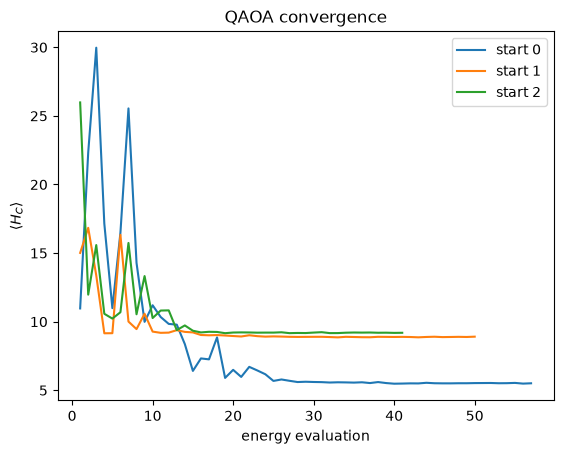

In [8]:
for k, hist in enumerate(data["history"]):
    plt.plot(range(1, len(hist) + 1), hist, label=f"start {k}")
plt.xlabel("energy evaluation")
plt.ylabel(r"$\langle H_C\rangle$")
plt.title("QAOA convergence")
plt.legend()
plt.show()

## Stop and think: what did the loop produce?

1. **The energy $\langle H_C\rangle$ is an average over bitstrings.** It is
   *not* the cost of one tour. A low average means probability has moved toward
   low-energy strings, but a lot of it can still sit on invalid ones, which
   carry large penalties. That is why the curve levels off well above the cost
   of the best tour.
2. **The final answer is a distribution.** We sample the optimized circuit and
   look at *which bitstrings appear*. The best tour is the cheapest valid string
   that shows up, not the minimum of the curve.
3. **Different starts land in different places.** Compare the curves: each start
   ends at its own value, so local minima are real. Hence the restarts.
4. **Two jobs for QAOA.** The optimizer must first learn to put probability on
   *valid tours* (because penalties are large) and only then to prefer *cheap*
   ones (because the cost differences are small). With few layers, the first job
   is easier than the second. Look for this in Step 4: valid tours may show up
   in nearly equal proportions regardless of cost.

*Try it:* raise `reps` to 3 or `starts` to 6 and rerun this section. Does the
invalid fraction printed in Step 4 shrink? Do cheaper tours become more likely
than expensive ones?

## Step 4: Analysis

We now do what the quantum computer cannot: look at the samples. For every
distinct bitstring we decode the tour (or mark it invalid), compute its cost,
and sort. We then draw

- the shortest tour found, as a loop over the cities with the cost of each leg,
  and
- the **tour spectrum**: every possible tour sorted by cost, with the
  probability the circuit sampled it, and the probability of an invalid sample.

A tour and its reverse are different bitstrings, so they appear as separate rows
in the ranking (with equal cost when the table is symmetric).


4 cities, aer_simulator, 4096 shots
Invalid samples: 73.7%
Distinct valid tours sampled: 6

rank     cost     prob  tour
   1    95.00    5.32%  Troy -> Saratoga -> Schenectady -> Albany -> Troy
   2    95.00    4.49%  Troy -> Albany -> Schenectady -> Saratoga -> Troy
   3   105.00    4.47%  Troy -> Albany -> Saratoga -> Schenectady -> Troy
   4   105.00    4.44%  Troy -> Schenectady -> Saratoga -> Albany -> Troy
   5   120.00    3.93%  Troy -> Saratoga -> Albany -> Schenectady -> Troy
   6   120.00    3.69%  Troy -> Schenectady -> Albany -> Saratoga -> Troy

Saved /tmp/tsp_result.png


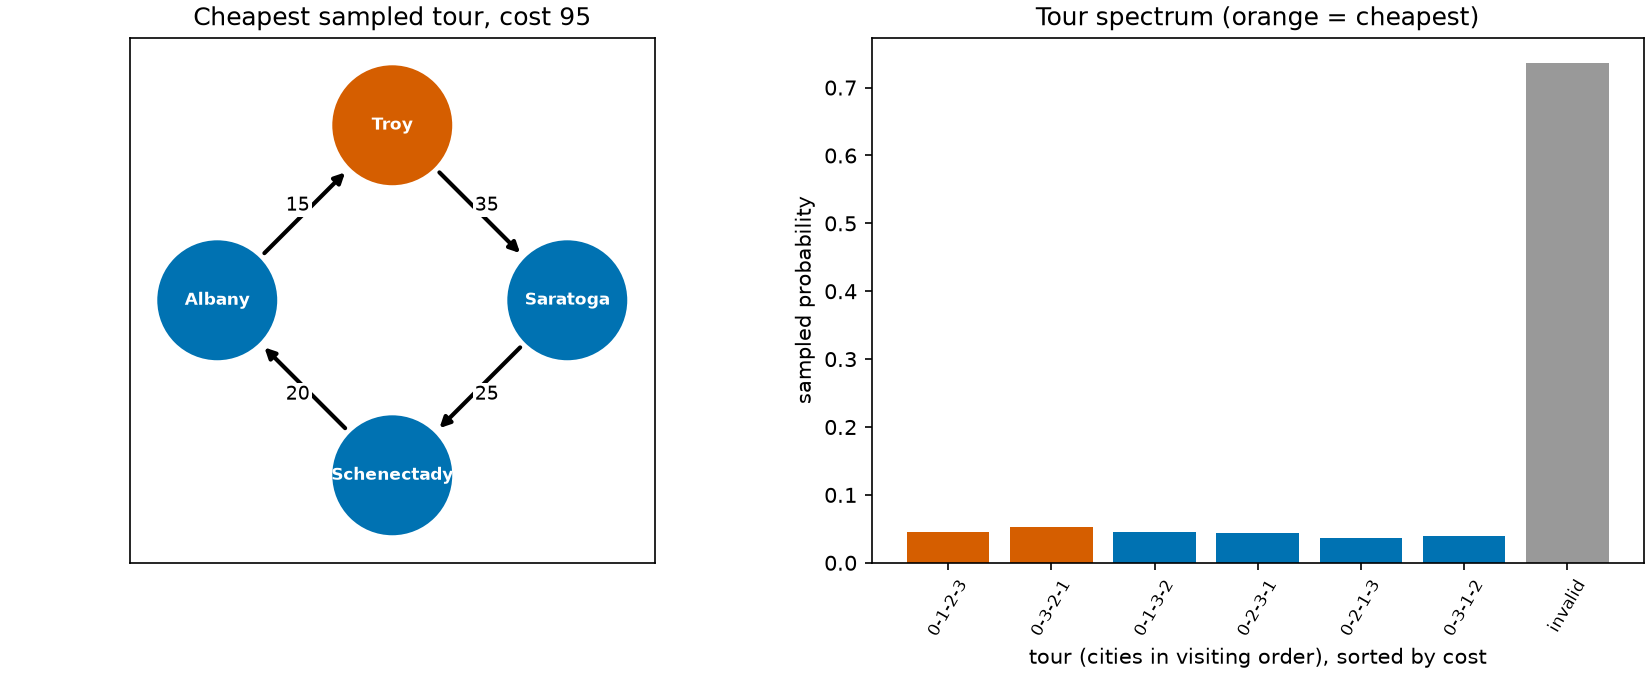

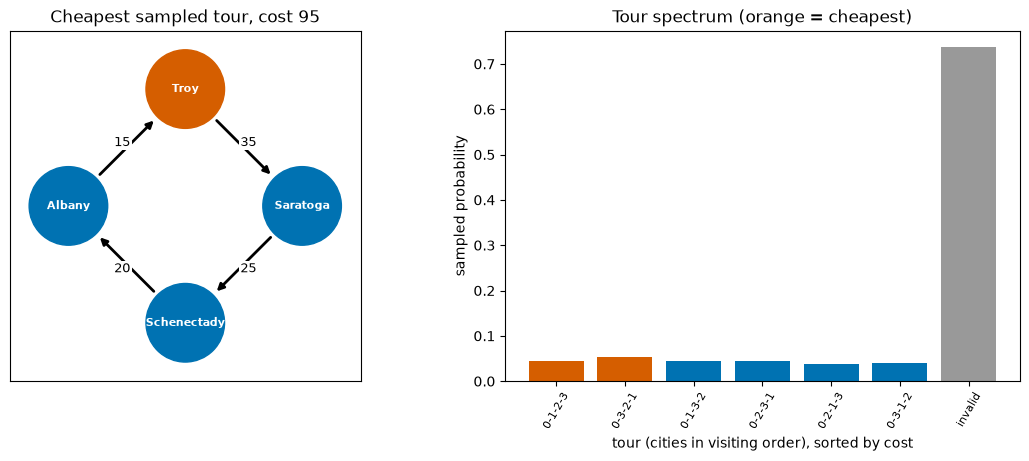

In [9]:
out = Path(tempfile.gettempdir()) / "tsp_result.png"
analysis.analyze(data, out, top=10)
Image(out)

## Reading the results

- **Ranked list.** Rows are distinct valid tours, sorted by cost and then
  probability. Pairs with the same cost are usually a tour and its reverse.
- **Shortest tour.** The arrows show the order of visits, labeled with the cost
  of each leg. The orange city is the fixed start.
- **Spectrum.** Orange bars are the cheapest tours. If they are taller than the
  blue ones, QAOA is preferring cheap tours. If all the colored bars are about
  equal, the circuit has learned to produce valid tours but not yet to rank
  them. The gray bar is the fraction of samples that were not tours at all. A
  large gray bar is the cost of penalty-based encodings at small circuit depth.

## What to try next

1. Raise `reps` and `starts` and see whether the orange bars grow relative to
   the blue ones.
2. Add a fifth city (16 qubits). Watch how the circuit depth and the invalid
   fraction change.
3. Change the penalty weight in `ops.default_penalty` and see how it trades
   validity against cost.
4. Set `backend_name` to a real device. Compare the invalid fraction against the
   simulator, which shows what hardware noise costs.
5. Run the same problem from the command line:
   `python optimization/main.py optimization/example_cities.json`.
6. The same recipe (encode, build $H$, run QAOA, decode) solves lattice protein
   folding. See the `folding` notebook for a problem where the encoding choice
   matters much more.